           AttackName  Runs  MeanEfficiency  StdEfficiency       MeanSLO  \
2            Currency    22        1.028755       0.290814  27739.454545   
1            Checkout    22        0.894727       0.262805  41437.090909   
3  Entire Application     9        0.720026       0.326418  20367.333333   
0           AddToCart    11        0.609804       0.394590  13755.636364   
4      Index Flooding    11        0.419351       0.171931  10278.818182   

   MeanRequests  MeanResource      95CI  
2  27019.545455   1340.954545  0.121523  
1  45277.500000   2610.954545  0.109819  
3  28390.444444   1101.555556  0.213260  
0  22801.181818   1221.000000  0.233188  
4  24521.181818   1185.181818  0.101604  
\begin{tabular}{lrrrrrrr}
\toprule
AttackName & Runs & MeanEfficiency & StdEfficiency & MeanSLO & MeanRequests & MeanResource & 95CI \\
\midrule
Currency & 22 & 1.029 & 0.291 & 27739.455 & 27019.545 & 1340.955 & 0.122 \\
Checkout & 22 & 0.895 & 0.263 & 41437.091 & 45277.500 & 2610.955 & 0.1

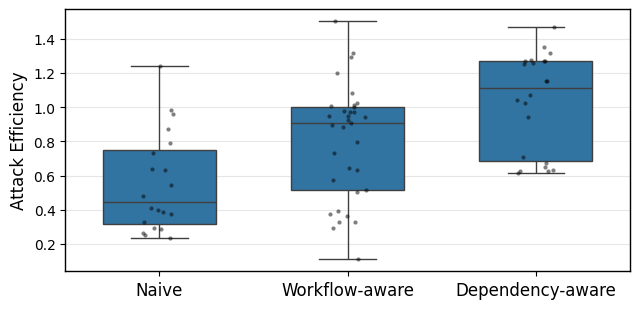

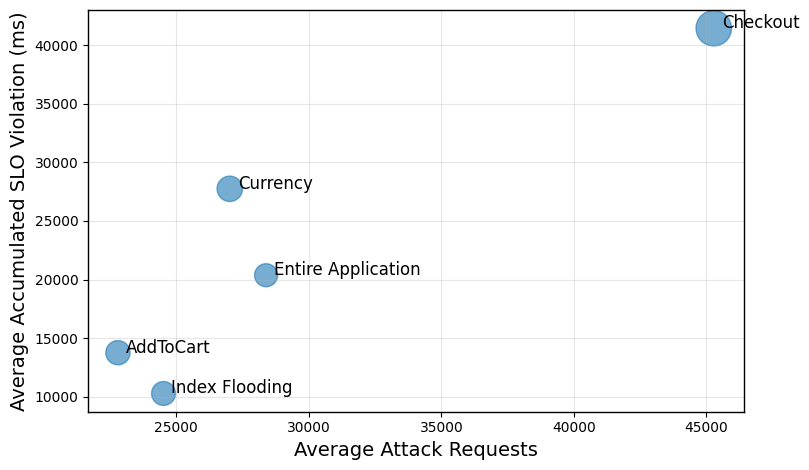


Reproduction completed successfully.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# Load Data
# ============================================================

df = pd.read_csv("./artifact/data/experiment_summary.csv")

# Only experiments with 40 attackers
df = df[df["users"] == 40].copy()

# ============================================================
# Selected attacks
# ============================================================

attack_map = {

    "index: 4,":
        ("Index Flooding", "Naive"),

    "all: 1,":
        ("Entire Application", "Naive"),

    "addToCart: 4, viewCart: 1, emptyCart: 1,":
        ("AddToCart", "Workflow-aware"),

    "checkout: 4,":
        ("Checkout", "Workflow-aware"),

    "setCurrency: 4, browseProduct: 0, browseProductByID: 1,":
        ("Currency", "Dependency-aware")
}

df = df[df["target"].isin(attack_map.keys())].copy()

# ============================================================
# Add attack name and category
# ============================================================

df["AttackName"] = df["target"].apply(lambda x: attack_map[x][0])

df["AttackType"] = df["target"].apply(lambda x: attack_map[x][1])

# ============================================================
# Attack Efficiency
# ============================================================

df["AttackEfficiency"] = (
    df["slo_violation_sum"] /
    df["total_requests"]
)

# ============================================================
# Summary per attack
# ============================================================

summary_attack = (

    df.groupby("AttackName")

    .agg(

        Runs=("AttackEfficiency", "count"),

        MeanEfficiency=("AttackEfficiency", "mean"),

        StdEfficiency=("AttackEfficiency", "std"),

        MeanSLO=("slo_violation_sum", "mean"),

        MeanRequests=("total_requests", "mean"),

        MeanResource=("total_resource_usage", "mean")

    )

    .reset_index()

)

summary_attack["95CI"] = (

    1.96 *

    summary_attack["StdEfficiency"] /

    np.sqrt(summary_attack["Runs"])

)

summary_attack = summary_attack.sort_values(
    "MeanEfficiency",
    ascending=False
)

summary_attack.to_csv(
    "./artifact/tables/Individual_Attacks.csv",
    index=False
)

print(summary_attack)

print(summary_attack.to_latex(
    index=False,
    float_format="%.3f"
))

# ============================================================
# Summary per attack category
# ============================================================

summary_type = (

    df.groupby("AttackType")

    .agg(

        Runs=("AttackEfficiency", "count"),

        MeanEfficiency=("AttackEfficiency", "mean"),

        StdEfficiency=("AttackEfficiency", "std"),

        MeanSLO=("slo_violation_sum", "mean"),

        MeanRequests=("total_requests", "mean"),

        MeanResource=("total_resource_usage", "mean")

    )

    .reset_index()

)

summary_type["95CI"] = (

    1.96 *

    summary_type["StdEfficiency"] /

    np.sqrt(summary_type["Runs"])

)

summary_type = summary_type.sort_values(
    "MeanEfficiency",
    ascending=False
)

summary_type.to_csv(
    "./artifact/tables/Attack_Summary.csv",
    index=False
)

print(summary_type)

print(summary_type.to_latex(
    index=False,
    float_format="%.3f"
))

# ============================================================
# Figure 1: Attack Efficiency
# ============================================================

order = [
    "Naive",
    "Workflow-aware",
    "Dependency-aware"
]

plt.figure(figsize=(6.5, 3.2))

sns.boxplot(
    data=df,
    x="AttackType",
    y="AttackEfficiency",
    order=order,
    width=0.6,
)

sns.stripplot(
    data=df,
    x="AttackType",
    y="AttackEfficiency",
    order=order,
    color="black",
    size=3,
    alpha=0.5,
)

plt.ylabel("Attack Efficiency", fontsize=12)
plt.xlabel("")
plt.grid(axis="y", alpha=0.3)

plt.xticks(fontsize=12)

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_linewidth(1)
    spine.set_color("black")

plt.tight_layout()

plt.savefig(
    "./artifact/figures/AttackEfficiency_Box.pdf",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ============================================================
# Figure 2: EDoS Landscape
# ============================================================

plt.figure(figsize=(8.2, 4.8))

sizes = summary_attack["MeanResource"] / 4

plt.scatter(
    summary_attack["MeanRequests"],
    summary_attack["MeanSLO"],
    s=sizes,
    alpha=0.6
)

for _, row in summary_attack.iterrows():
    plt.text(
        row["MeanRequests"] + 300,
        row["MeanSLO"],
        row["AttackName"],
        fontsize=12
    )

plt.xlabel("Average Attack Requests", fontsize=14)
plt.ylabel("Average Accumulated SLO Violation (ms)", fontsize=14)

plt.grid(alpha=0.3)

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_linewidth(1)
    spine.set_color("black")

plt.tight_layout()

plt.savefig(
    "./artifact/figures/EDoS_Landscape.pdf",
    dpi=600,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nReproduction completed successfully.")